# P2 / 01: does lagged VIX predict daily reversal returns? (H1, faithful)

Protocol: [`001_claude_p2_liquidity_provision_preregistration.md`](../../discussions/Liquidity_Provision/001_claude_p2_liquidity_provision_preregistration.md), section 3. Paper: Nagel (2012), *Evaporating Liquidity*.

- **Portfolio:** Lehmann / Lo–MacKinlay contrarian weights $w_i \propto -(r_i - \bar r)$ on the day's return, +1 long / −1 short, price ≥ $5. Signal at the close of d, trade at the close of d+1, held one session.
- **Regime:** VIX at the signal close above its trailing 250-session median.
- **Gates** (α = 0.025, HAC 5 lags, one-sided): N1 slope on VIX > 0 and N2 slope on the high-regime dummy > 0, both on 2016-12 → 2025 gross returns; N3 the regime-gated portfolio net of measured costs on 2020–2025 (bootstrap lower bound > 0 at blocks 10/20/40, 2× mean > 0).

In [1]:
import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, p1, p2, s04, s05, s05b
from equity_trading.alpaca import ALPACA_VERSION, download_years, sample_quote_spreads
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("P2_SYNTHETIC") == "1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
CFG = p2.P2Config()
PER_YEAR, WINDOW_S = 4, 3.0                          # S05b quote samples (reused from cache)
YEARS_D = list(range(2016, 2026))                    # 1Day bars; 2016 is baseline warm-up
YEARS_Q = list(range(2020, 2026))                    # measured-cost years; 2026 not used
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / f"15Min_w{WINDOW_S:g}s"
tag = ("synthetic_" if SYNTHETIC else "") + f"alpaca{ALPACA_VERSION}_p2{p2.P2_VERSION}"
OUT = ROOT / "notebooks" / "Liquidity_Provision" / ("01_synthetic" if SYNTHETIC else "01")
OUT.mkdir(parents=True, exist_ok=True)
print(f"synthetic={SYNTHETIC} | alpha={CFG.alpha} | skip={CFG.skip}")

synthetic=False | alpha=0.025 | skip=1


## 1. Data: daily bars 2016–2025, VIX, measured costs

In [2]:
t0 = time.time()
if SYNTHETIC:
    C, V, VIX = p2.synthetic_daily_vix(n_stocks=150, years=list(range(2016, 2022)), slope=0.25)
    COST = pd.DataFrame(3e-4, index=C.index, columns=C.columns)
    CFG = replace(CFG, end="2021-12-31", n_label_placebo=20, n_boot=2000)
else:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
    STOCKS = sorted(constituents["Symbol"])
    download_years(STOCKS, "1Day", YEARS_D, workers=8)
    C, _, V = p1.load_daily(STOCKS, YEARS_D)
    C, V = C.dropna(axis=1, how="all"), V.dropna(axis=1, how="all")
    VIX = p2.load_vix()
    SESSIONS = s05b.sample_sessions(YEARS_Q, PER_YEAR, seed=42)
    missing = [d for d in SESSIONS if not (QUOTE_CACHE / f"{d}.parquet").exists()]
    if missing:
        QUOTE_CACHE.mkdir(parents=True, exist_ok=True)
        for d in missing:
            sample_quote_spreads(list(C.columns), d, s05b.slot_starts(YEARS_Q, d), window_s=WINDOW_S, cache_dir=QUOTE_CACHE)
    samples = pd.concat([pd.read_parquet(QUOTE_CACHE / f"{d}.parquet") for d in SESSIONS], ignore_index=True)
    COST = p1.daily_cost(C.index, list(C.columns), s05b.cost_model(samples))   # 2016-2019: per-symbol fallback (no quotes)
RET = C.pct_change()
VIX = VIX.reindex(C.index).ffill(limit=2)
REG = p2.vix_regime(VIX, CFG)
print(f"{C.shape[1]} stocks, {len(C)} sessions {C.index[0].date()} to {C.index[-1].date()}; VIX coverage "
      f"{VIX.notna().mean():.1%}; high-regime share {REG.mean():.1%}; ready in {time.time() - t0:.0f}s")

1Day: 153 batches to download (1509 symbol-years), 8 parallel requests
  10/153 batches, 23,436 bars, 0.1 min elapsed, ~1 min left
  20/153 batches, 45,990 bars, 0.1 min elapsed, ~1 min left
  30/153 batches, 69,174 bars, 0.2 min elapsed, ~1 min left
  40/153 batches, 93,114 bars, 0.2 min elapsed, ~1 min left
  50/153 batches, 115,864 bars, 0.3 min elapsed, ~1 min left
  60/153 batches, 137,607 bars, 0.3 min elapsed, ~1 min left
  70/153 batches, 160,368 bars, 0.4 min elapsed, ~0 min left
  80/153 batches, 183,601 bars, 0.5 min elapsed, ~0 min left
  90/153 batches, 207,415 bars, 0.5 min elapsed, ~0 min left
  100/153 batches, 230,419 bars, 0.6 min elapsed, ~0 min left
  110/153 batches, 252,758 bars, 0.6 min elapsed, ~0 min left
  120/153 batches, 275,997 bars, 0.7 min elapsed, ~0 min left
  130/153 batches, 299,089 bars, 0.7 min elapsed, ~0 min left
  140/153 batches, 322,991 bars, 0.8 min elapsed, ~0 min left
  150/153 batches, 346,169 bars, 0.9 min elapsed, ~0 min left
  153/153 ba

D:\Anaconda\envs\equity-trading\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
D:\Anaconda\envs\equity-trading\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
D:\Anaconda\envs\equity-trading\Lib\site-packages\yfinance\multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inp

501 stocks, 2514 sessions 2016-01-04 to 2025-12-31; VIX coverage 100.0%; high-regime share 46.3%; ready in 101s


## 2. Contrarian portfolio and its dependence on VIX (N1, N2)

,intercept,slope,t,p_one_sided,n
N1 gross ~ VIX,-0.000010,0.000006,0.106283,0.457679,2283.0
N2 gross ~ 1{high VIX},-0.000143,0.000533,1.230095,0.109331,2283.0


,days,vix_mean,mean_gross_bps
vix_quintile,,,
Q1,457,11.525,1.266
Q2,456,14.325,0.035
Q3,457,17.036,-3.551
Q4,456,20.681,3.604
Q5,457,30.106,3.900


,gross_bps_day,cost_bps_day,net_bps_day,high_regime_share
2016,20.783,7.126,13.657,0.000
2017,-3.161,7.320,-10.481,0.131
2018,0.811,7.134,-6.323,0.861
2019,0.726,7.210,-6.484,0.397
2020,11.299,6.788,4.511,0.763
2021,-7.984,6.979,-14.963,0.159
2022,8.249,7.265,0.984,0.753
2023,2.118,6.705,-4.587,0.068
2024,1.369,7.469,-6.100,0.512
2025,-5.696,11.709,-17.404,0.572


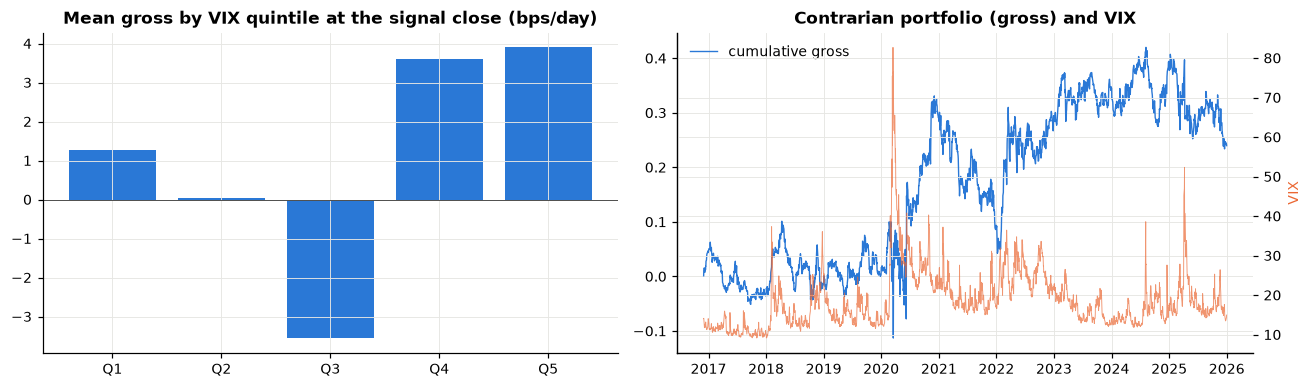

In [3]:
ELIG = (C >= CFG.min_price) & RET.notna()
W = p2.contrarian_weights(RET, ELIG)
UNG = p1.ls_returns(W, RET, COST, CFG.skip)
H1W = UNG.index[(UNG.index >= CFG.h1_start) & (UNG.index <= CFG.end)]
x_vix = p2.aligned_signal(VIX, UNG.index, CFG.skip)
x_reg = p2.aligned_signal(REG.astype(float), UNG.index, CFG.skip)
N1 = p2.hac_slope(UNG.loc[H1W, "gross"], x_vix.loc[H1W], CFG.hac_lags)
N2 = p2.hac_slope(UNG.loc[H1W, "gross"], x_reg.loc[H1W], CFG.hac_lags)
display(pd.DataFrame({"N1 gross ~ VIX": N1, "N2 gross ~ 1{high VIX}": N2}).T)
d = pd.DataFrame({"gross_bps": 1e4 * UNG.loc[H1W, "gross"], "vix": x_vix.loc[H1W]}).dropna()
d["vix_quintile"] = pd.qcut(d["vix"], 5, labels=[f"Q{i}" for i in range(1, 6)])
BYQ = d.groupby("vix_quintile", observed=True).agg(days=("gross_bps", "size"), vix_mean=("vix", "mean"), mean_gross_bps=("gross_bps", "mean"))
BYY = (1e4 * UNG.loc[H1W, ["gross", "cost", "net"]]).groupby(H1W.year).mean().rename(columns=lambda c: c + "_bps_day")
BYY["high_regime_share"] = x_reg.loc[H1W].groupby(H1W.year).mean()
BYQ.to_csv(OUT / "gross_by_vix_quintile.csv", float_format="%.5g"); BYY.to_csv(OUT / "by_year.csv", float_format="%.5g")
display(BYQ.round(3)); display(BYY.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(BYQ.index.astype(str), BYQ["mean_gross_bps"], color="#2a78d6"); ax[0].axhline(0, color="#444", lw=0.6)
ax[0].set_title("Mean gross by VIX quintile at the signal close (bps/day)")
cg = UNG.loc[H1W, "gross"].cumsum()
ax[1].plot(cg.index, cg, color="#2a78d6", lw=0.9, label="cumulative gross")
a2 = ax[1].twinx(); a2.plot(VIX.loc[H1W].index, VIX.loc[H1W], color="#eb6834", lw=0.6, alpha=0.7)
a2.set_ylabel("VIX", color="#eb6834"); ax[1].set_title("Contrarian portfolio (gross) and VIX"); ax[1].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

## 3. Regime-gated portfolio net of measured costs, 2020–2025 (N3)

,gross_bps_day,cost_bps_day,net_bps_day,net2x_bps_day,sharpe_net,days_active
ungated,1.570,7.815,-6.245,-14.06,-0.789,1508.0
VIX-gated,2.084,3.877,-1.793,-5.67,-0.260,763.0


,mean,lo,hi
10,-1.793,-6.883,3.574
20,-1.793,-6.620,3.201
40,-1.793,-6.534,2.695


N1_vix_slope                                False
N2_vix_regime                               False
N3_economic                                 False
replication_verdict                NO_REPLICATION
economic_verdict       NOT_PROFITABLE_AFTER_COSTS
dtype: object

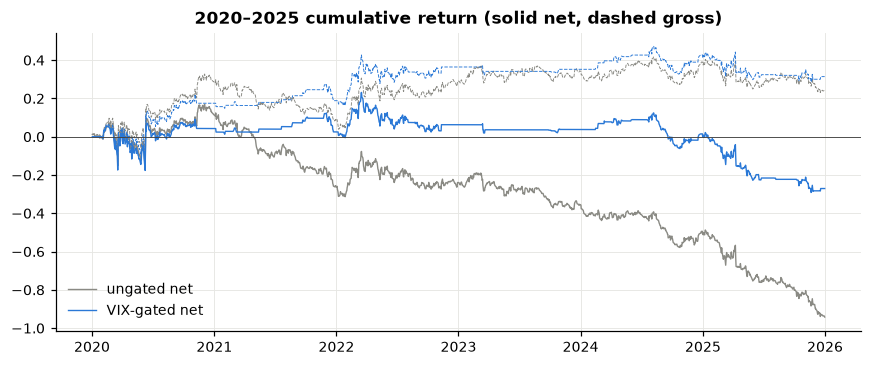

{
  "N1_vix_slope": false,
  "N2_vix_regime": false,
  "N3_economic": false,
  "replication_verdict": "NO_REPLICATION",
  "economic_verdict": "NOT_PROFITABLE_AFTER_COSTS"
}


In [4]:
EW = UNG.index[(UNG.index >= CFG.econ_start) & (UNG.index <= CFG.end)]
GAT = p1.ls_returns(p2.gate_by_regime(W, REG), RET, COST, CFG.skip).loc[EW]
def stats(df):
    sd = df.std()
    return {"gross_bps_day": 1e4 * df.gross.mean(), "cost_bps_day": 1e4 * df.cost.mean(), "net_bps_day": 1e4 * df.net.mean(),
            "net2x_bps_day": 1e4 * (df.gross - 2 * df.cost).mean(), "sharpe_net": np.sqrt(252) * df.net.mean() / sd.net if sd.net > 0 else np.nan,
            "days_active": int((df.cost > 0).sum())}
ECON = pd.DataFrame({"ungated": stats(UNG.loc[EW]), "VIX-gated": stats(GAT)}).T
BOOT = {b: p1.block_bootstrap(GAT["net"].to_numpy(), b, CFG.n_boot, CFG.seed, CFG.alpha) for b in CFG.blocks}
G = p2.gates_h1(N1, N2, BOOT, float((GAT.gross - 2 * GAT.cost).mean()), CFG.alpha)
display(ECON.round(3)); display((pd.DataFrame(BOOT, index=["mean", "lo", "hi"]).T * 1e4).round(3)); display(pd.Series(G))
pd.concat({"ungated": UNG.loc[EW], "gated": GAT}, axis=1).to_csv(OUT / "daily_returns_2020_2025.csv", float_format="%.6g")
fig, ax = plt.subplots(figsize=(8, 3.4))
for name, df, col in (("ungated", UNG.loc[EW], "#8a8a84"), ("VIX-gated", GAT, "#2a78d6")):
    ax.plot(df.index, df.net.cumsum(), color=col, lw=0.9, label=f"{name} net"); ax.plot(df.index, df.gross.cumsum(), color=col, lw=0.6, ls="--")
ax.axhline(0, color="#444", lw=0.6); ax.legend(frameon=False); ax.set_title("2020–2025 cumulative return (solid net, dashed gross)")
plt.tight_layout(); plt.show()
summary = {"study": "P2-01", "synthetic": SYNTHETIC, "config": CFG.as_dict(), "n_stocks": int(C.shape[1]),
           "N1": N1, "N2": N2, "by_vix_quintile": BYQ.to_dict(orient="index"), "econ": ECON.to_dict(orient="index"),
           "bootstrap_gated_net_bps": {str(k): [1e4 * x for x in v] for k, v in BOOT.items()}, "gates": G,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "p2": p2.P2_VERSION, "p1": p1.P1_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir())}, indent=2))
print(json.dumps(G, indent=2))